# Sea-level rise projections at Pacific tide gauges

Station counterpart of the [regional sea-level projection maps](regional_indicators.ipynb). It applies the National [tide-gauge projection analysis](../../National/sea_level/a_sea_level_projections.ipynb) to **every UHSLC tide gauge inside, or within 0.5° of, a Pacific EEZ** (the station set of the historical regional notebook), using the IPCC AR6 projections **with vertical land motion** (relative sea level, as in the [NASA Pacific Flooding Analysis Tool](https://sealevel.nasa.gov/flooding-analysis-tool-pacific-islands/sea-level-rise)):

1. matching of each UHSLC gauge to the nearest AR6 tide-gauge location;
2. maps of projected relative sea-level change by 2100 at every gauge;
3. median and likely range per station for every SSP;
4. the contribution of vertical land motion (with minus without VLM);
5. tables for SSPs and end-of-century global warming levels.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level_station_projections.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level_station_projections.py).')
sys.path.insert(0, str(repo_root / 'functions'))

import projections_regional as reg
from sea_level import pacific_uhslc_stations, save_dict_json
from sea_level_projections import colour_limits
from sea_level_station_projections import (
    GWL_SCENARIOS, SSP_SCENARIOS, load_ar6_locations, match_stations, plot_station_map_panels, plot_station_ranges,
    scenario_label,
)
from sst import PacificSST

## 1. Configuration

In [3]:
data_dir = repo_root / 'data'
raw_dir = data_dir / 'projections' / 'sea_level'
locations_cache = data_dir / 'projections' / 'regional' / 'sl_ar6_vlm_medium_locations.nc'
novlm_cache = data_dir / 'projections' / 'regional' / 'sl_ar6_novlm_medium_pacific.nc'   # from regional_indicators.ipynb
eez_file = data_dir / 'regional' / 'Pacific_EEZs' / 'Pacific_EEZs.shp'
fig_dir = repo_root / 'outputs' / 'figures' / 'regional_pacific'
tab_dir = repo_root / 'outputs' / 'tables' / 'regional_pacific'
for directory in (fig_dir, tab_dir):
    directory.mkdir(parents=True, exist_ok=True)

pacific_extent = (125, 245, -35, 35)
start, end = '1993-01-01', '2025-12-31'     # stations with Fast Delivery data in this period
ssp_scenarios = list(SSP_SCENARIOS)
gwl_scenarios = list(GWL_SCENARIOS)
map_year = 2100
years = (2050, 2100)
max_match_km = 30
seq_cmap = 'afmhot_r'
force_download = False

## 2. Stations and AR6 locations

UHSLC Fast Delivery stations in the map window are kept when they lie inside, or within 0.5° of, a Pacific EEZ. Each is matched to the nearest AR6 tide-gauge location (PSMSL) within 30 km; otherwise the nearest ocean grid cell is used and the station is flagged.

In [4]:
eez = gpd.read_file(eez_file).to_crs(4326)
pacific = PacificSST(data_raw=None, data=None, eez=eez, extent=pacific_extent)

stations = pacific_uhslc_stations(pacific_extent, start, end)
points = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(((stations['lon'] + 180) % 360) - 180, stations['lat']), crs=4326)
with warnings.catch_warnings():  # distances in degrees are adequate for a 0.5° tolerance
    warnings.simplefilter('ignore')
    in_eez = gpd.sjoin_nearest(points, eez[['Country', 'geometry']].rename(columns={'Country': 'eez'}),
                               how='inner', max_distance=0.5)
stations = in_eez.drop(columns=['geometry', 'index_right']).drop_duplicates('uhslc_id').reset_index(drop=True)

locs = load_ar6_locations(raw_dir, locations_cache, ssp_scenarios + gwl_scenarios, force_download=force_download)
stations = match_stations(locs, stations[['uhslc_id', 'name', 'country', 'eez', 'lon', 'lat']], max_km=max_match_km)
stations = stations.dropna(subset=['ar6_location']).assign(ar6_location=lambda d: d['ar6_location'].astype(int))
stations['lon360'] = stations['lon'] % 360
stations = stations.sort_values('lon360').reset_index(drop=True)
stations['label'] = stations['name'] + ' (' + stations['eez'] + ')'
print(f"{len(stations)} UHSLC stations; {int((stations['ar6_kind'] == 'tide gauge').sum())} matched to an AR6 tide gauge, "
      f"{int((stations['ar6_kind'] == 'grid cell').sum())} to a grid cell.")
stations[['uhslc_id', 'name', 'eez', 'ar6_kind', 'ar6_location', 'ar6_distance_km']]

69 UHSLC stations; 48 matched to an AR6 tide gauge, 21 to a grid cell.


,uhslc_id,name,eez,ar6_kind,ar6_location,ar6_distance_km
0,437,Peleliu,Palau,grid cell,1008301340,29.9
1,7,Malakal,Palau,tide gauge,1252,2.2
2,436,Kamesang,Palau,tide gauge,1252,18.5
3,438,Imekang,Palau,tide gauge,1252,28.7
4,8,Yap,Micronesia,grid cell,1008001380,55.7
...,...,...,...,...,...,...
64,455,Rangiroa Atoll,French Polynesia,grid cell,1010502120,32.1
65,454,Makemo,French Polynesia,grid cell,1010702160,57.4
66,31,Nuku Hiva,French Polynesia,grid cell,1009902200,14.2
67,17,Hiva Oa,French Polynesia,grid cell,1010002210,22.0


## 3. Projected relative sea-level change at each station

In [5]:
change = locs['change'].sel(location=xr.DataArray(stations['ar6_location'].values, dims='station'))
change = change.assign_coords(station=stations['uhslc_id'].values)   # (scenario, quantile, year, station), cm
for scenario in ssp_scenarios + gwl_scenarios:
    for year in years:
        for q in (0.17, 0.5, 0.83):
            stations[f'{scenario}_{year}_q{q:g}'] = change.sel(scenario=scenario, year=year, quantile=q).values.round(1)

### Maps of the median change by 2100

Each circle is a tide gauge; all panels share a sequential scale from the smallest to the largest station value. Differences between nearby stations come mostly from vertical land motion.

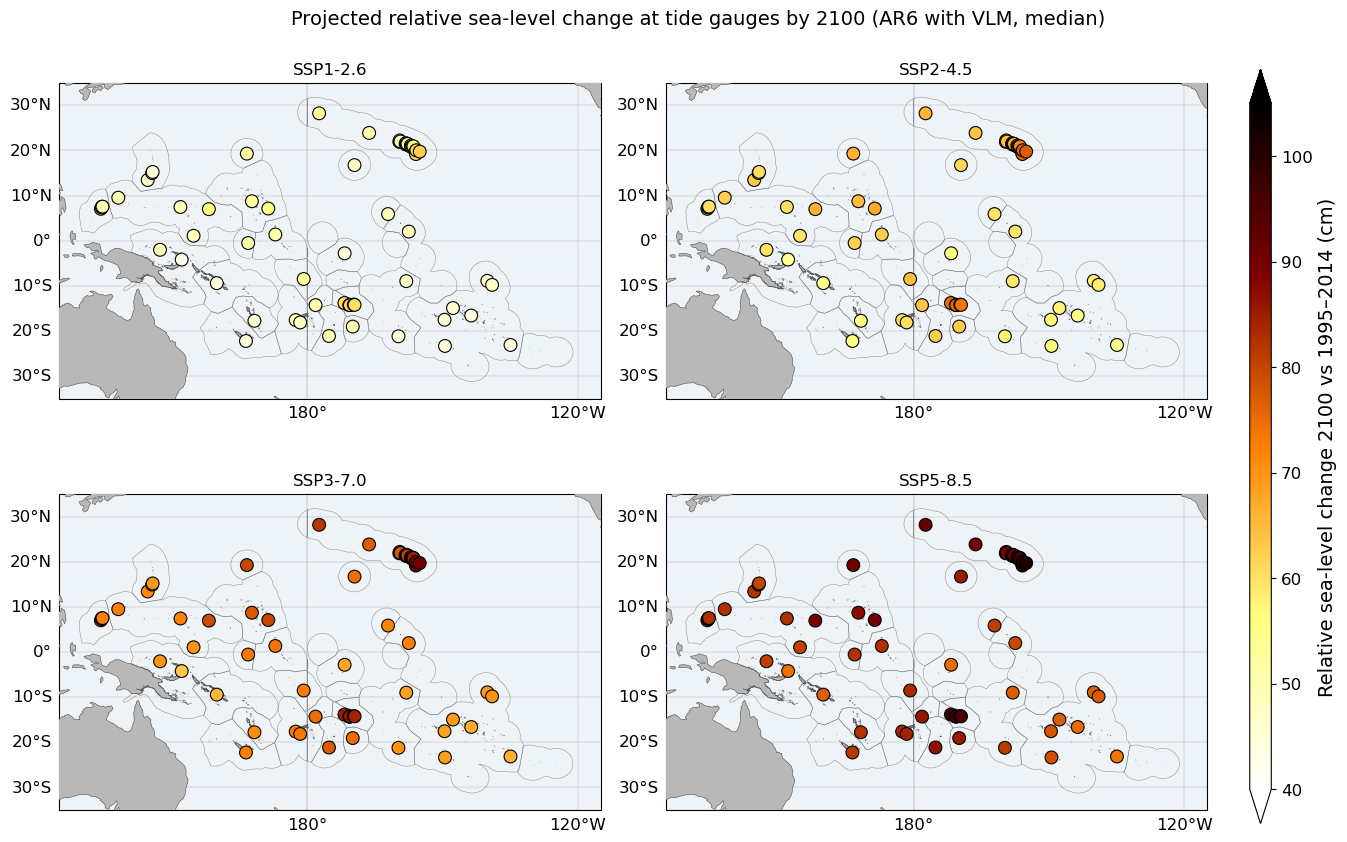

In [6]:
cols = {ssp_label: f'{s}_{map_year}_q0.5' for s, ssp_label in ((s, scenario_label(s)) for s in ssp_scenarios)}
vmin, vmax, _ = colour_limits(xr.DataArray(stations[list(cols.values())].to_numpy()), 5)
fig = plot_station_map_panels(
    stations, cols, pacific, f'Projected relative sea-level change at tide gauges by {map_year} (AR6 with VLM, median)',
    f'Relative sea-level change {map_year} vs 1995–2014 (cm)', cmap=seq_cmap, vmin=vmin, vmax=vmax,
    filename=fig_dir / f'PRJ_SL_stations_change_{map_year}_ar6_vlm_pacific.png',
)
plt.show()

### Median and likely range per station

Stations ordered from west to east.

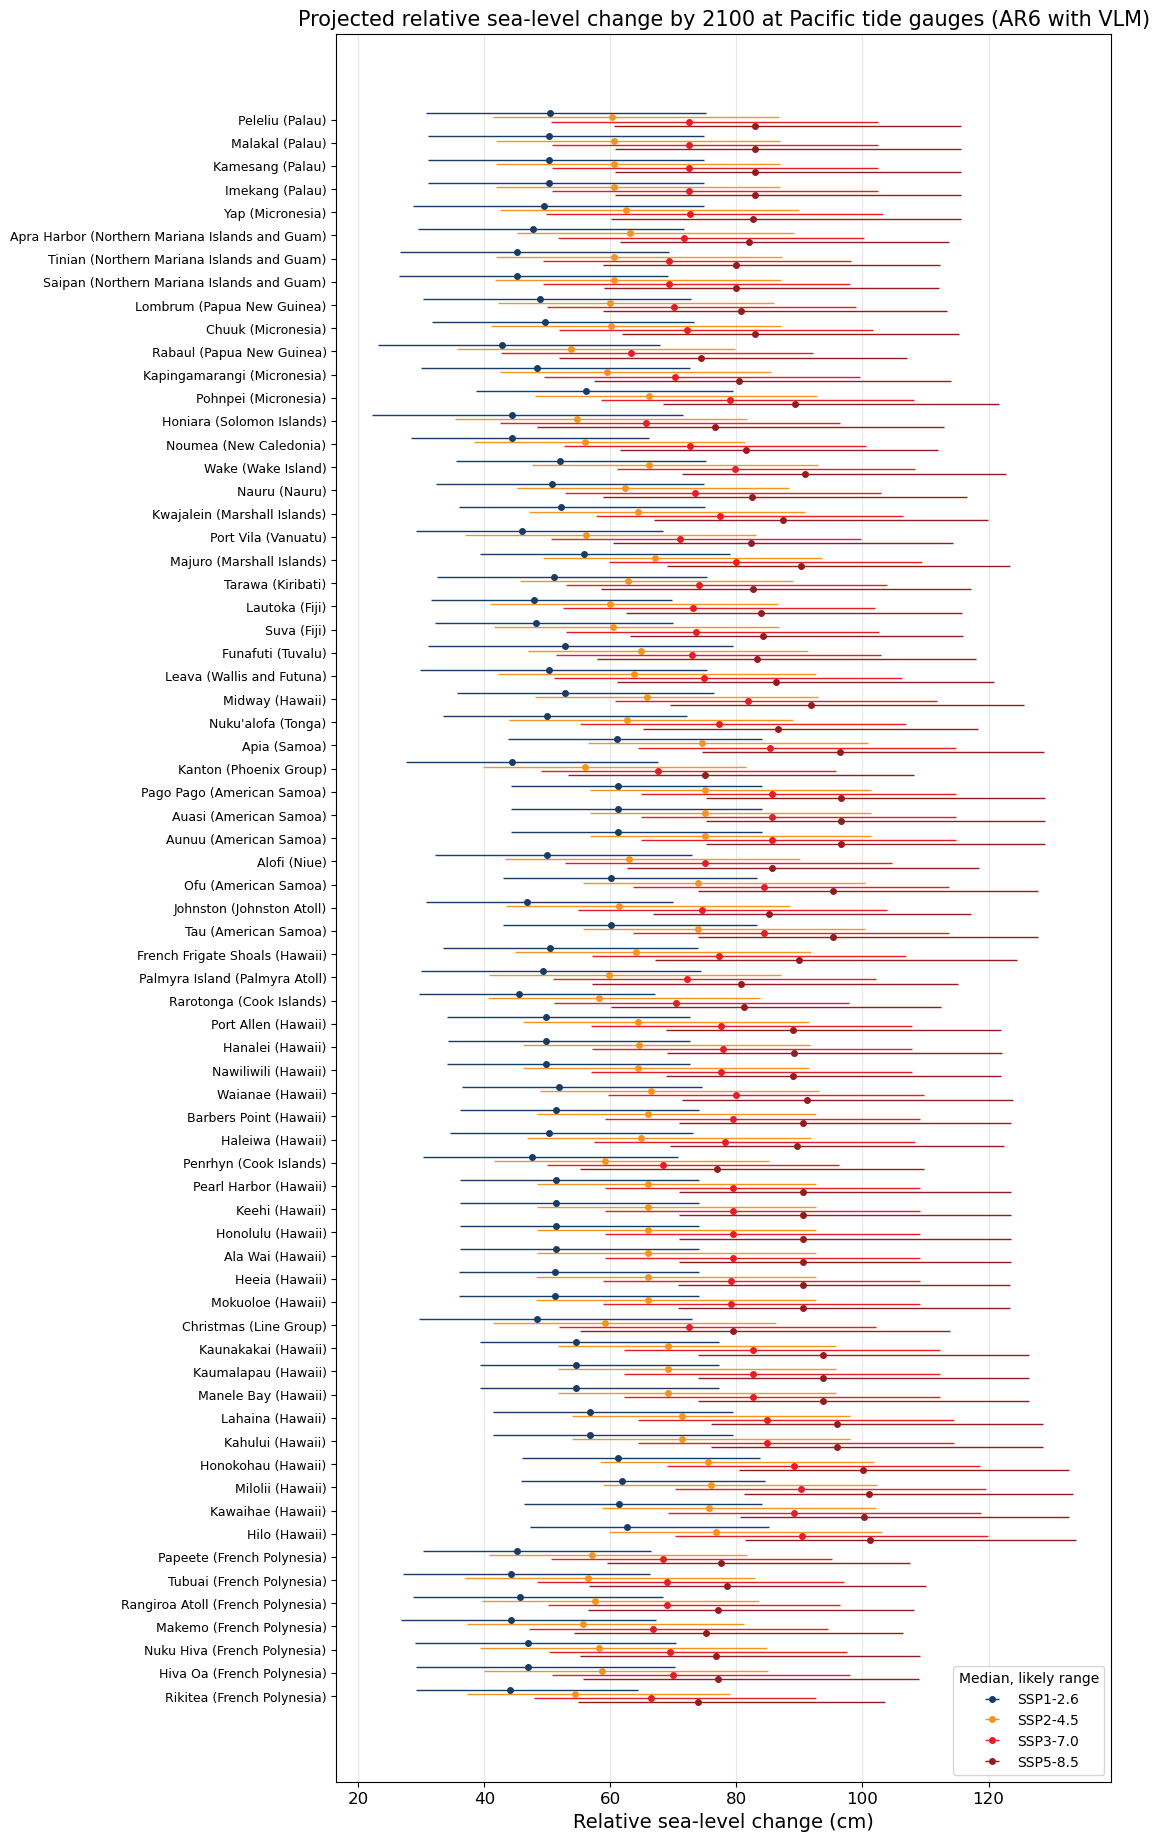

In [7]:
fig, ax = plot_station_ranges(stations, ssp_scenarios, map_year,
                              f'Projected relative sea-level change by {map_year} at Pacific tide gauges (AR6 with VLM)')
fig.savefig(fig_dir / f'PRJ_SL_stations_ranges_{map_year}_ar6_vlm_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Contribution of vertical land motion

Median change with VLM minus median change without VLM (absolute, from the [regional maps notebook](regional_indicators.ipynb)) at the same AR6 tide-gauge location, for SSP2-4.5 in 2100. Positive values (red) indicate subsidence that adds to relative sea-level rise; negative values (blue) indicate uplift. A diverging scale centred on zero is used because the sign matters here.

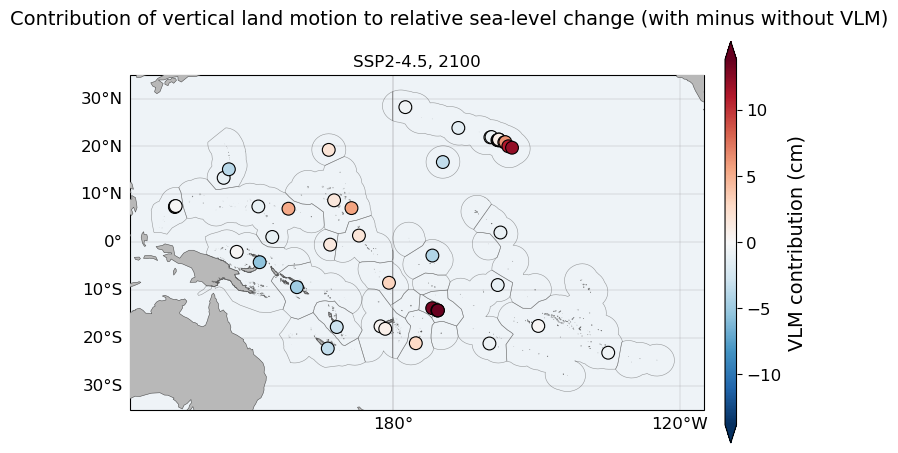

,label,vlm_ssp245_2100_cm
31,Aunuu (American Samoa),13.8
30,Auasi (American Samoa),13.8
29,Pago Pago (American Samoa),13.8
27,Apia (Samoa),13.3
61,Hilo (Hawaii),12.1
60,Kawaihae (Hawaii),10.9
57,Kahului (Hawaii),6.3
56,Lahaina (Hawaii),6.3
19,Majuro (Marshall Islands),5.5
12,Pohnpei (Micronesia),5.2


In [8]:
vlm_col = f'vlm_ssp245_{map_year}_cm'
if novlm_cache.is_file():
    novlm = xr.load_dataset(novlm_cache)
    gauge_ids = set(novlm.gauge.values.tolist())
    without = [float(novlm['gauge_change'].sel(scenario='ssp245', quantile=0.5, year=map_year, gauge=loc))
               if (kind == 'tide gauge' and loc in gauge_ids) else np.nan
               for loc, kind in zip(stations['ar6_location'], stations['ar6_kind'])]
    stations[vlm_col] = (stations[f'ssp245_{map_year}_q0.5'] - np.array(without)).round(1)
    fig = plot_station_map_panels(
        stations.dropna(subset=[vlm_col]), {f'SSP2-4.5, {map_year}': vlm_col}, pacific,
        'Contribution of vertical land motion to relative sea-level change (with minus without VLM)',
        'VLM contribution (cm)', cmap='RdBu_r', diverging=True, ncols=1,
        filename=fig_dir / f'PRJ_SL_stations_vlm_contribution_{map_year}_pacific.png',
    )
    plt.show()
    display(stations.dropna(subset=[vlm_col]).sort_values(vlm_col, ascending=False)[['label', vlm_col]].head(10))
else:
    print('Run regional_indicators.ipynb first to create the no-VLM cache.')

## 5. Tables

Median (likely range) in cm relative to 1995–2014 by 2050 and 2100, for the SSPs and the end-of-century warming levels. The full table with every quantile is saved to `outputs/tables/regional_pacific/`.

In [9]:
def fmt(row, scenario, year):
    return f"{row[f'{scenario}_{year}_q0.5']:.0f} ({row[f'{scenario}_{year}_q0.17']:.0f}–{row[f'{scenario}_{year}_q0.83']:.0f})"

summary = pd.DataFrame({
    f'{scenario_label(s)} {y}': [fmt(r, s, y) for _, r in stations.iterrows()]
    for s in ssp_scenarios for y in years
}, index=stations['label'])
gwl_summary = pd.DataFrame({
    f'{scenario_label(s)} {map_year}': [fmt(r, s, map_year) for _, r in stations.iterrows()] for s in gwl_scenarios
}, index=stations['label'])

stations.drop(columns=['lon360']).to_csv(tab_dir / 'PRJ_SL_stations_ar6_vlm_pacific.csv', index=False)
summary.to_csv(tab_dir / 'PRJ_SL_stations_summary_ssp_pacific.csv')
gwl_summary.to_csv(tab_dir / 'PRJ_SL_stations_summary_gwl_pacific.csv')
display(summary)
gwl_summary

,SSP1-2.6 2050,SSP1-2.6 2100,SSP2-4.5 2050,SSP2-4.5 2100,SSP3-7.0 2050,SSP3-7.0 2100,SSP5-8.5 2050,SSP5-8.5 2100
label,,,,,,,,
Peleliu (Palau),20 (14–28),50 (31–75),21 (15–30),60 (41–87),22 (16–31),72 (51–102),24 (18–33),83 (61–116)
Malakal (Palau),20 (14–28),50 (31–75),21 (15–30),60 (42–87),22 (16–31),72 (51–102),24 (18–33),83 (61–116)
Kamesang (Palau),20 (14–28),50 (31–75),21 (15–30),60 (42–87),22 (16–31),72 (51–102),24 (18–33),83 (61–116)
Imekang (Palau),20 (14–28),50 (31–75),21 (15–30),60 (42–87),22 (16–31),72 (51–102),24 (18–33),83 (61–116)
Yap (Micronesia),20 (13–29),49 (29–75),21 (14–31),62 (42–90),22 (14–32),73 (50–103),24 (16–34),83 (60–116)
...,...,...,...,...,...,...,...,...
Rangiroa Atoll (French Polynesia),19 (12–27),46 (29–68),20 (14–29),58 (40–84),21 (15–29),69 (50–96),23 (16–32),77 (56–108)
Makemo (French Polynesia),18 (11–26),44 (27–67),19 (13–28),56 (37–81),20 (14–29),67 (47–95),22 (15–31),75 (54–106)
Nuku Hiva (French Polynesia),19 (12–28),47 (29–70),20 (14–29),58 (39–85),21 (14–29),70 (50–98),23 (16–32),77 (55–109)


,+1.5 °C 2100,+2.0 °C 2100,+3.0 °C 2100,+4.0 °C 2100,+5.0 °C 2100
label,,,,,
Peleliu (Palau),51 (31–74),60 (41–84),68 (52–92),78 (59–105),86 (68–116)
Malakal (Palau),51 (31–74),60 (41–84),68 (53–92),78 (60–104),86 (68–116)
Kamesang (Palau),51 (31–74),60 (41–84),68 (53–92),78 (60–104),86 (68–116)
Imekang (Palau),51 (31–74),60 (41–84),68 (53–92),78 (60–104),86 (68–116)
Yap (Micronesia),51 (30–74),59 (38–84),70 (52–95),77 (59–104),84 (64–116)
...,...,...,...,...,...
Rangiroa Atoll (French Polynesia),46 (30–67),54 (38–76),66 (49–91),72 (55–98),85 (67–114)
Makemo (French Polynesia),44 (28–65),53 (36–75),64 (47–89),70 (52–96),82 (64–112)
Nuku Hiva (French Polynesia),46 (29–67),55 (36–78),65 (48–91),72 (53–100),84 (65–114)


In [10]:
metrics = {
    'source': locs.attrs['source'], 'product': locs.attrs['product'], 'vertical_land_motion': locs.attrs['vertical_land_motion'],
    'stations': int(len(stations)), 'matched_to_tide_gauge': int((stations['ar6_kind'] == 'tide gauge').sum()),
}
for s in ssp_scenarios:
    v = stations[f'{s}_{map_year}_q0.5']
    metrics[f'{s}_{map_year}_station_median_range_cm'] = [round(float(v.min()), 1), round(float(v.median()), 1), round(float(v.max()), 1)]
save_dict_json(metrics, tab_dir, 'PRJ_SL_stations_summary_metrics_pacific.json')
pd.Series(metrics).to_frame('value')

,value
source,"IPCC AR6 sea-level projections, Garner et al. ..."
product,"regional total, medium confidence"
vertical_land_motion,included
stations,69
matched_to_tide_gauge,48
ssp126_2100_station_median_range_cm,"[42.8, 50.2, 62.6]"
ssp245_2100_station_median_range_cm,"[53.7, 63.8, 76.7]"
ssp370_2100_station_median_range_cm,"[63.2, 75.0, 90.4]"
ssp585_2100_station_median_range_cm,"[73.9, 86.2, 101.2]"


## Interpretation and reproducibility notes

- **Source:** IPCC AR6 sea-level projections (Garner et al., 2021, Zenodo [10.5281/zenodo.6382554](https://doi.org/10.5281/zenodo.6382554)), `ar6-regional-confidence` (with VLM), total, medium confidence; values relative to 1995–2014.
- **Relative vs absolute:** station values include vertical land motion and are what the tide gauges should record; the gridded maps of the regional notebook exclude it. The VLM contribution isolates the difference at each gauge; AR6 extrapolates observed VLM rates linearly, which is uncertain where motion is episodic (e.g. post-seismic subsidence).
- **Matching:** each UHSLC gauge uses the nearest AR6 (PSMSL) tide-gauge location within 30 km; flagged stations use the nearest grid cell, whose VLM term is generic.
- **Scenarios:** SSPs are emissions scenarios; the warming-level projections group AR6 samples by end-of-century warming, as in the NASA tool.
- **Uncertainty:** ranges are the AR6 likely range (17–83 %); medium confidence excludes low-likelihood, high-impact ice-sheet processes.
- **Flooding:** projected flood days are computed station by station in the National notebook [Projected minor flooding](../../National/sea_level/b_sea_level_flooding.ipynb).